# Xuất 5 biểu đồ chính của mục 4 (EDA)

**Dữ liệu:** `cleaned.csv` (bộ dữ liệu giá nhà Ames, Iowa – 1460 dòng, 81 cột). **Biến mục tiêu:** `SalePrice`.

Notebook này tạo lại **5 biểu đồ** dùng trong báo cáo (Hình 1–5, mục 4 và mục 5) và lưu vào `reports/figures/`. Mọi số liệu được tính trực tiếp từ `cleaned.csv`, nên nếu dữ liệu thay đổi chỉ cần chạy lại từ trên xuống.

| Hình | Nội dung | File |
|---|---|---|
| 1 | Phân phối `SalePrice` (cột 50.000 USD, trung vị và trung bình) | `s4_fig1_saleprice_hist.png` |
| 2 | Tương quan Pearson giữa `SalePrice` và các biến diện tích / chất lượng | `s4_fig2_corr_bars.png` |
| 3 | Giá trung vị theo `OverallQual` (kèm khoảng 25%–75%) | `s4_fig3_price_by_quality.png` |
| 4 | Giá trung vị theo `Neighborhood` | `s4_fig4_price_by_neighborhood.png` |
| 5 | Giá trung vị theo nhóm `GrLivArea` × nhóm `OverallQual` | `s4_fig5_area_by_quality.png` |

## 1. Import thư viện & đọc dữ liệu

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

DATA_PATH = "../data/processed/cleaned.csv"
FIG_OUT = "../reports/figures/"
os.makedirs(FIG_OUT, exist_ok=True)

# Màu: xám cho dữ liệu, xanh cho điểm nhấn (cùng một nhóm = cùng một màu ở mọi hình)
ACCENT, MUTED, REF, TEXT, SUB = "#2B7BD8", "#C4C4B8", "#8A8A8A", "#1F1F1F", "#6B6B6B"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9A9A9A", "axes.titleweight": "normal",
    "axes.titlesize": 13, "axes.titlelocation": "left",
})

def vn(x, d=0):
    """Định dạng số kiểu Việt Nam: dấu chấm hàng nghìn, dấu phẩy thập phân."""
    s = f"{x:,.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

def kfmt(v):
    """Làm tròn nửa lên (124.500 -> 125k), tránh làm tròn 'chẵn' của Python."""
    return int(v / 1000 + 0.5)

def header(fig, title, subtitle, top_in=0.8):
    """Tiêu đề (nêu phát hiện) và dòng phụ ở góc trên trái, không đè lên biểu đồ."""
    h = fig.get_size_inches()[1]
    fig.text(0.01, 1 - 0.08 / h, title, fontsize=13, va="top", ha="left", color=TEXT)
    fig.text(0.01, 1 - 0.40 / h, subtitle, fontsize=9.5, va="top", ha="left", color=SUB)
    fig.tight_layout(rect=[0, 0, 1, 1 - top_in / h])

def savefig(name):
    plt.savefig(os.path.join(FIG_OUT, name), bbox_inches="tight", facecolor="white")

df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["", "NA"])
print("Kích thước:", df.shape)

Kích thước: (1460, 81)


## 2. Hình 1 – Phân phối giá bán

Giá lệch phải: trung bình cao hơn trung vị. Số căn ghi trên từng cột; trung vị và trung bình đánh dấu dưới trục.

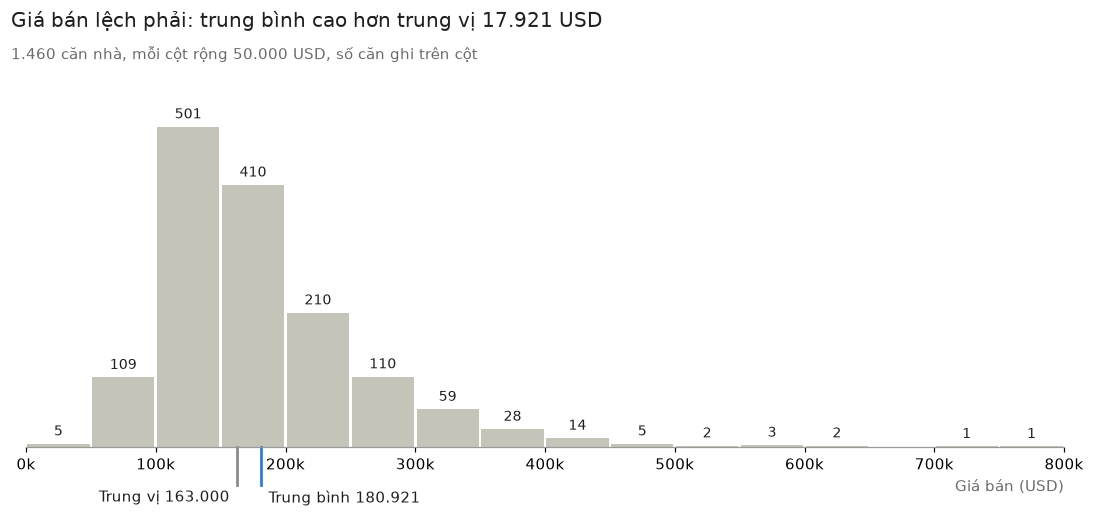

In [2]:
step, maxv = 50_000, 800_000
edges = np.arange(0, maxv + step, step)
counts, _ = np.histogram(df["SalePrice"], bins=edges)
med, mean = df["SalePrice"].median(), df["SalePrice"].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(edges[:-1] + step / 2, counts, width=step * 0.96, color=MUTED)
for x, n in zip(edges[:-1] + step / 2, counts):
    if n > 0:
        ax.text(x, n + 8, vn(n), ha="center", va="bottom", fontsize=9, color=TEXT)

# Đánh dấu trung vị / trung bình dưới trục (tránh đè lên số căn trên cột)
ax.plot([med, med], [0, -60], color=REF, lw=1.8, clip_on=False)
ax.plot([mean, mean], [0, -60], color=ACCENT, lw=1.8, clip_on=False)
ax.text(med - 6_000, -68, f"Trung vị {vn(med)}", ha="right", va="top", fontsize=9.5, color=TEXT)
ax.text(mean + 6_000, -68, f"Trung bình {vn(mean)}", ha="left", va="top", fontsize=9.5, color=TEXT)

ax.set_xlim(0, maxv); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xticks(np.arange(0, maxv + 1, 100_000))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v/1000)}k"))
ax.set_xlabel("Giá bán (USD)", loc="right", color=SUB)
ax.set_ylim(0, counts.max() * 1.08)
header(fig, f"Giá bán lệch phải: trung bình cao hơn trung vị {vn(mean - med)} USD",
       f"{vn(len(df))} căn nhà, mỗi cột rộng {vn(step)} USD, số căn ghi trên cột", top_in=0.75)
savefig("s4_fig1_saleprice_hist.png")
plt.show()

## 3. Hình 2 – Tương quan với `SalePrice`

Biến chữ thứ bậc được mã hóa `Po=1 … Ex=5`, giá trị "không có" (`NoBasement`, …) = 0 (giống notebook EDA).

In [3]:
qual_map = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
d = df.copy()
for c in ["ExterQual", "KitchenQual", "BsmtQual"]:
    d[c] = d[c].map(qual_map).fillna(0)

vars_ = [  # (biến, nhóm)
    ("OverallQual", "Chất lượng"), ("GrLivArea", "Diện tích"), ("ExterQual", "Chất lượng"),
    ("KitchenQual", "Chất lượng"), ("GarageArea", "Diện tích"), ("TotalBsmtSF", "Diện tích"),
    ("1stFlrSF", "Diện tích"), ("BsmtQual", "Chất lượng"), ("MasVnrArea", "Diện tích"),
    ("LotArea", "Diện tích"), ("OverallCond", "Chất lượng"),
]
corr = pd.DataFrame(
    [(v, g, d[v].corr(d["SalePrice"])) for v, g in vars_], columns=["var", "group", "r"]
).sort_values("r", ascending=False).reset_index(drop=True)
corr

,var,group,r
0,OverallQual,Chất lượng,0.790982
1,GrLivArea,Diện tích,0.708624
2,ExterQual,Chất lượng,0.682639
3,KitchenQual,Chất lượng,0.659600
4,GarageArea,Diện tích,0.623431
5,TotalBsmtSF,Diện tích,0.613581
6,1stFlrSF,Diện tích,0.605852
7,BsmtQual,Chất lượng,0.585207
8,MasVnrArea,Diện tích,0.472614
9,LotArea,Diện tích,0.263843


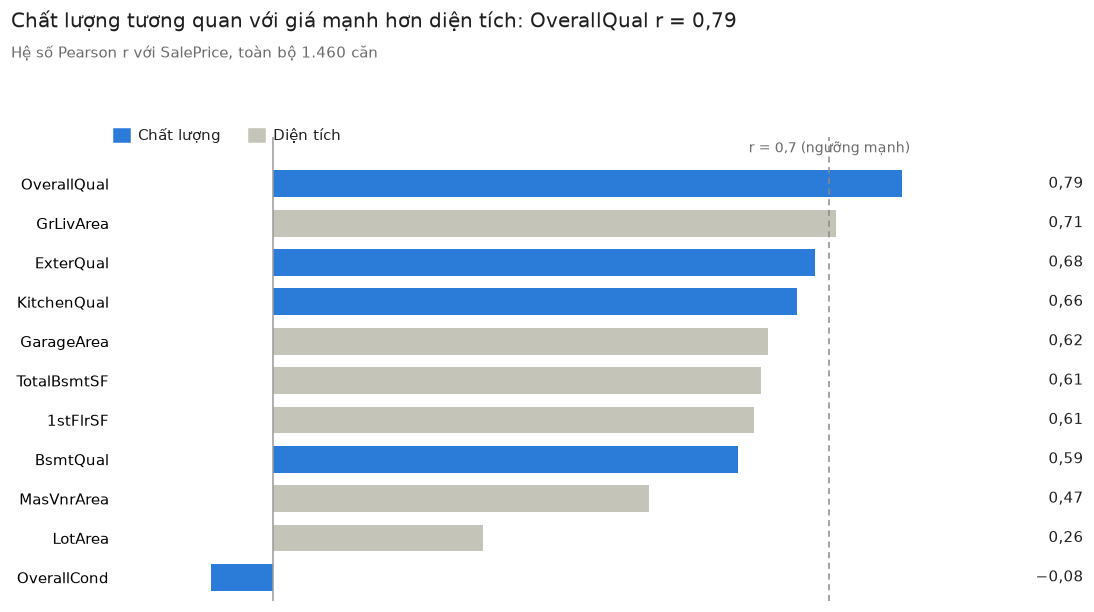

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(corr))[::-1]
colors = [ACCENT if g == "Chất lượng" else MUTED for g in corr["group"]]
ax.barh(y, corr["r"], color=colors, height=0.68)
ax.axvline(0, color="#9A9A9A", lw=1)
ax.axvline(0.7, color=REF, lw=1, ls=(0, (4, 3)))
ax.text(0.7, len(corr) - 0.2, "r = 0,7 (ngưỡng mạnh)", ha="center", color=SUB, fontsize=9)

ax.set_yticks(y); ax.set_yticklabels(corr["var"])
xmax = 1.0
for yi, r in zip(y, corr["r"]):
    ax.text(xmax + 0.02, yi, vn(r, 2).replace("-", "−"), va="center", ha="right", color=TEXT, fontsize=10)
ax.set_xlim(-0.2, xmax + 0.02); ax.set_xticks([])
ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(corr) + 0.2)

top = corr.iloc[0]
for i, (name, col) in enumerate([("Chất lượng", ACCENT), ("Diện tích", MUTED)]):
    ax.add_patch(plt.Rectangle((-0.2 + i * 0.17, len(corr) + 0.05), 0.02, 0.35, color=col, clip_on=False))
    ax.text(-0.17 + i * 0.17, len(corr) + 0.22, name, va="center", fontsize=9.5, color=TEXT)
header(fig, f"Chất lượng tương quan với giá mạnh hơn diện tích: {top['var']} r = {vn(top['r'], 2)}",
       f"Hệ số Pearson r với SalePrice, toàn bộ {vn(len(df))} căn", top_in=1.0)
savefig("s4_fig2_corr_bars.png")
plt.show()

## 4. Hình 3 – Giá trung vị theo `OverallQual`

Cột = trung vị; thanh dọc = khoảng tứ phân vị 25%–75%. Mức 1–2 chỉ có 5 căn nên kém tin cậy.

In [5]:
g = df.groupby("OverallQual")["SalePrice"].agg(
    n="count", med="median", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75)
).reset_index()
g

,OverallQual,n,med,p25,p75
0,1,2,50150.0,44725.0,55575.0
1,2,3,60000.0,47655.5,60000.0
2,3,20,86250.0,75500.0,97500.0
3,4,116,108000.0,88000.0,125500.0
4,5,397,133000.0,118000.0,147000.0
5,6,374,160000.0,139125.0,181000.0
6,7,319,200141.0,179470.0,230750.0
7,8,168,269750.0,234557.5,306250.0
8,9,43,345000.0,318980.5,389716.0
9,10,18,432390.0,349375.0,472875.0


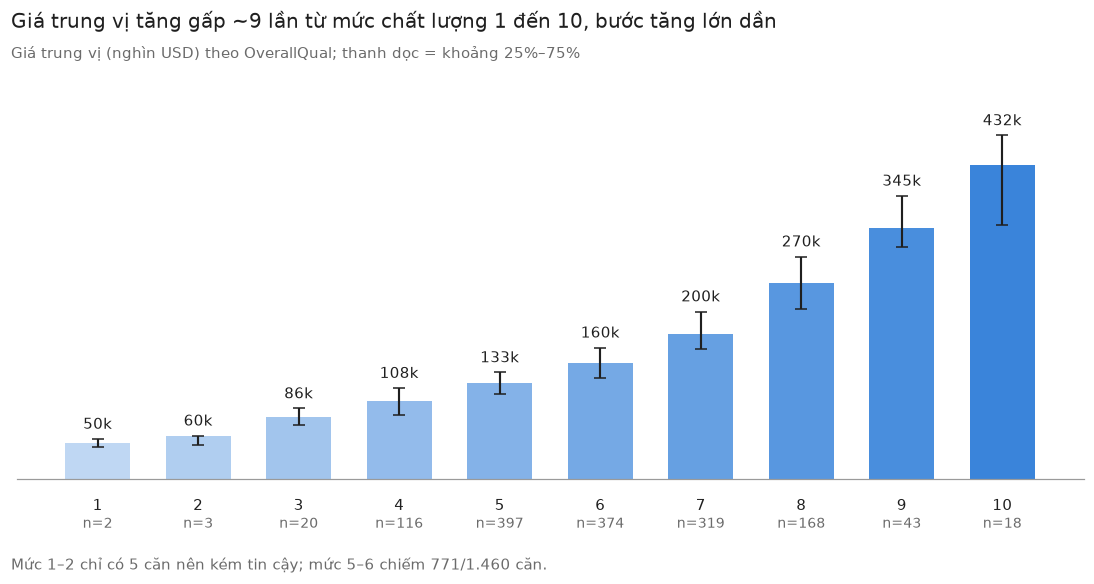

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(g))
alphas = 0.30 + 0.07 * np.arange(len(g))
for xi, (m, a) in enumerate(zip(g["med"], alphas)):
    ax.bar(xi, m, width=0.65, color=ACCENT, alpha=a)
ax.errorbar(x, g["med"], yerr=[g["med"] - g["p25"], g["p75"] - g["med"]],
            fmt="none", ecolor=TEXT, elinewidth=1.4, capsize=4)
for xi, r in g.iterrows():
    ax.text(xi, r["p75"] + 9_000, f"{kfmt(r['med'])}k", ha="center", va="bottom", color=TEXT)
    ax.text(xi, -26_000, f"{int(r['OverallQual'])}", ha="center", va="top", color=TEXT)
    ax.text(xi, -52_000, f"n={int(r['n'])}", ha="center", va="top", color=SUB, fontsize=9)

ax.set_xticks([]); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_ylim(0, g["p75"].max() * 1.1)
ratio = g["med"].iloc[-1] / g["med"].iloc[0]
header(fig, f"Giá trung vị tăng gấp ~{ratio:.0f} lần từ mức chất lượng 1 đến 10, bước tăng lớn dần",
       "Giá trung vị (nghìn USD) theo OverallQual; thanh dọc = khoảng 25%–75%", top_in=0.75)
small = int(g.loc[g["OverallQual"] <= 2, "n"].sum()); mid = int(g.loc[g["OverallQual"].isin([5, 6]), "n"].sum())
fig.text(0.01, -0.01, f"Mức 1–2 chỉ có {small} căn nên kém tin cậy; mức 5–6 chiếm {vn(mid)}/{vn(len(df))} căn.",
         color=SUB, fontsize=9.5, va="top")
savefig("s4_fig3_price_by_quality.png")
plt.show()

## 5. Hình 4 – Giá trung vị theo khu phố

In [7]:
nb = (df.groupby("Neighborhood")["SalePrice"].agg(n="count", med="median")
        .sort_values("med", ascending=False).reset_index())
all_med = df["SalePrice"].median()
nb.head(3)

,Neighborhood,n,med
0,NridgHt,77,315000.0
1,NoRidge,41,301500.0
2,StoneBr,25,278000.0


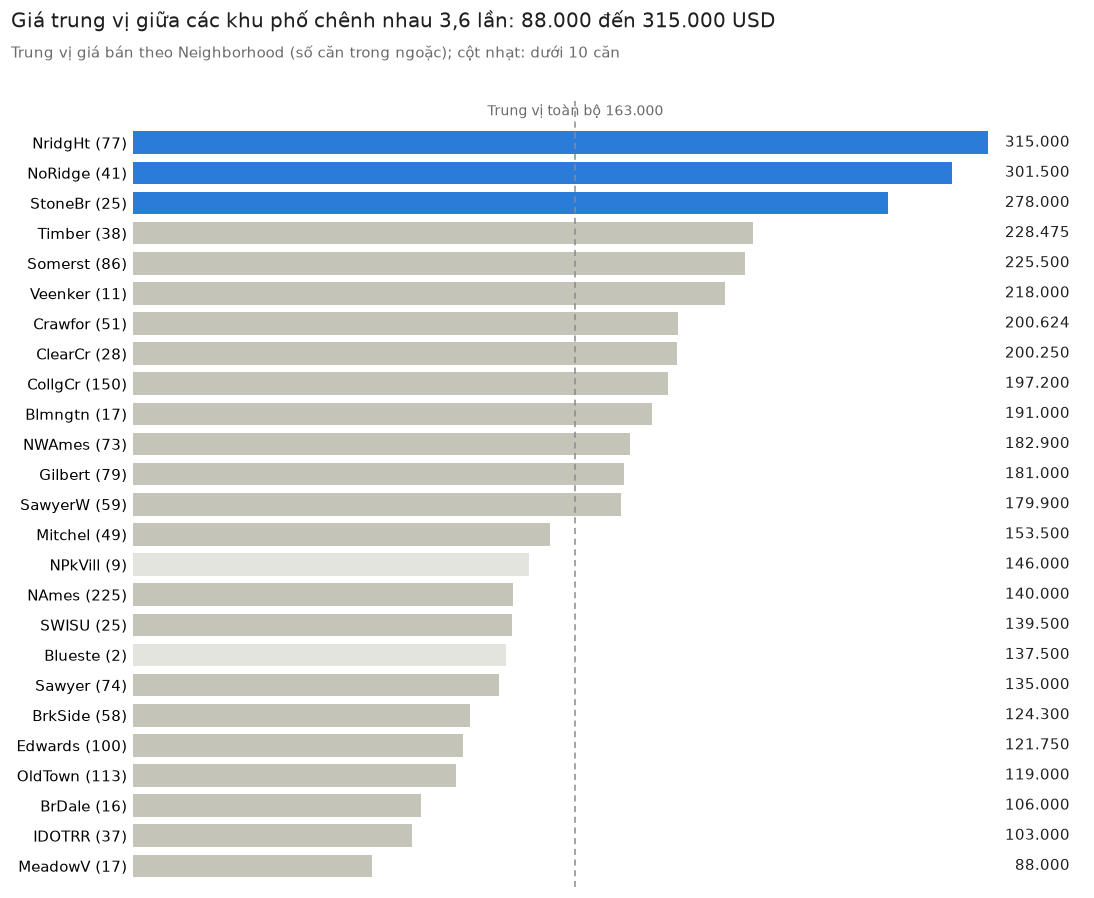

In [8]:
fig, ax = plt.subplots(figsize=(10, 8.2))
y = np.arange(len(nb))[::-1]
for yi, r in zip(y, nb.itertuples()):
    top3 = r.Index < 3
    ax.barh(yi, r.med, height=0.75, color=ACCENT if top3 else MUTED, alpha=0.45 if r.n < 10 else 1)
    ax.text(yi * 0 + 345_000, yi, vn(r.med), va="center", ha="right", color=TEXT)
ax.set_yticks(y); ax.set_yticklabels([f"{r.Neighborhood} ({r.n})" for r in nb.itertuples()])
ax.tick_params(axis="y", length=0)
ax.axvline(all_med, color=REF, lw=1, ls=(0, (4, 3)))
ax.text(all_med, len(nb) - 0.2, f"Trung vị toàn bộ {vn(all_med)}", ha="center", va="bottom", color=SUB, fontsize=9)
ax.set_xlim(0, 350_000); ax.set_xticks([])
ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False)
ax.set_ylim(-0.7, len(nb) + 0.4)
header(fig, f"Giá trung vị giữa các khu phố chênh nhau {vn(nb['med'].max()/nb['med'].min(), 1)} lần: "
            f"{vn(nb['med'].min())} đến {vn(nb['med'].max())} USD",
       "Trung vị giá bán theo Neighborhood (số căn trong ngoặc); cột nhạt: dưới 10 căn", top_in=0.75)
savefig("s4_fig4_price_by_neighborhood.png")
plt.show()

## 6. Hình 5 – Diện tích × chất lượng

Chỉ vẽ các ô có từ 10 căn trở lên.

In [9]:
band_labels = ["<1.000", "1.000–1.499", "1.500–1.999", "2.000+"]
tier_labels = ["1–4", "5–6", "7–8", "9–10"]
d5 = df.assign(
    band=pd.cut(df["GrLivArea"], [0, 1000, 1500, 2000, np.inf], labels=band_labels),
    tier=pd.cut(df["OverallQual"], [0, 4, 6, 8, 10], labels=tier_labels),
)
cell = (d5.groupby(["band", "tier"], observed=True)["SalePrice"].agg(n="count", med="median").reset_index())
cell = cell[cell["n"] >= 10]
cell.pivot(index="band", columns="tier", values="med")

tier,1–4,5–6,7–8,9–10
band,,,,
<1.000,86000.0,124500.0,NaN,NaN
1.000–1.499,108000.0,144000.0,185500.0,NaN
1.500–1.999,133716.0,168500.0,224950.0,322500.0
2.000+,NaN,192250.0,274300.0,415298.0


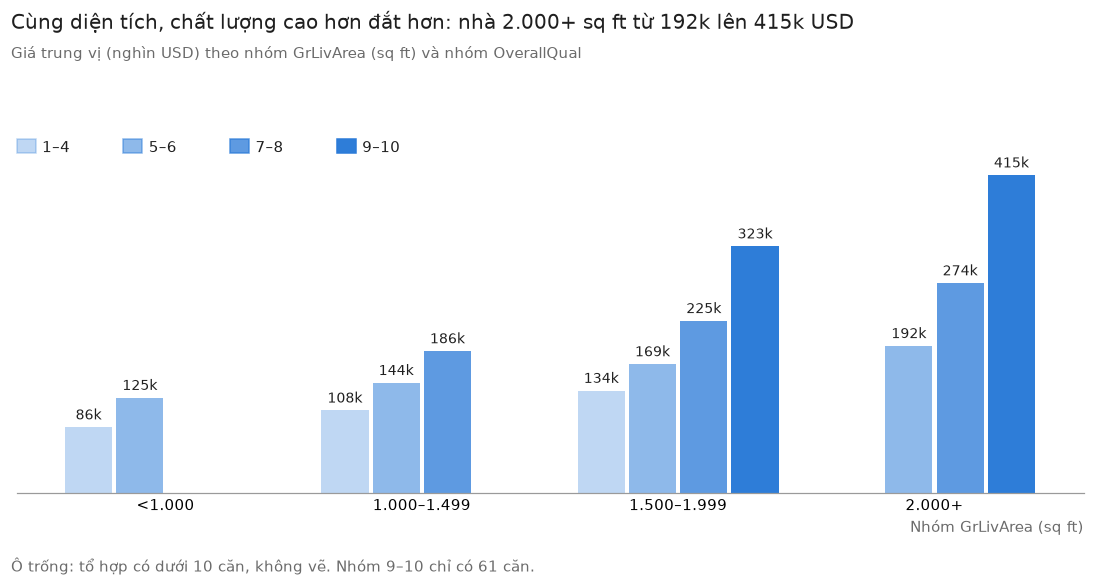

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
w = 0.2
for r in cell.itertuples():
    bi, k = band_labels.index(r.band), tier_labels.index(r.tier)
    xpos = bi + (k - 1.5) * w
    ax.bar(xpos, r.med, width=w * 0.92, color=ACCENT, alpha=0.30 + 0.23 * k)
    ax.text(xpos, r.med + 6_000, f"{kfmt(r.med)}k", ha="center", va="bottom", fontsize=9, color=TEXT)
ax.set_xticks(range(len(band_labels))); ax.set_xticklabels(band_labels)
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.tick_params(axis="x", length=0)
ax.set_xlabel("Nhóm GrLivArea (sq ft)", loc="right", color=SUB)

big = cell[cell["band"] == "2.000+"].sort_values("med")
_title = (f"Cùng diện tích, chất lượng cao hơn đắt hơn: nhà 2.000+ sq ft từ "
             f"{kfmt(big['med'].min())}k lên {kfmt(big['med'].max())}k USD")
for i, t in enumerate(tier_labels):
    ax.add_patch(plt.Rectangle((0.0 + i * 0.1, 1.02), 0.018, 0.04, transform=ax.transAxes,
                               color=ACCENT, alpha=0.30 + 0.23 * i, clip_on=False))
    ax.text(0.024 + i * 0.1, 1.022, t, transform=ax.transAxes, fontsize=9.5, color=TEXT)
n9 = int((df["OverallQual"] >= 9).sum())
fig.text(0.01, -0.01, f"Ô trống: tổ hợp có dưới 10 căn, không vẽ. Nhóm 9–10 chỉ có {n9} căn.",
         color=SUB, fontsize=9.5, va="top")
header(fig, _title, "Giá trung vị (nghìn USD) theo nhóm GrLivArea (sq ft) và nhóm OverallQual", top_in=1.05)
savefig("s4_fig5_area_by_quality.png")
plt.show()

## 7. Kiểm tra file đã lưu

In [11]:
for f in sorted(os.listdir(FIG_OUT)):
    if f.startswith("s4_fig"):
        print(f, f"{os.path.getsize(os.path.join(FIG_OUT, f))/1024:.0f} KB")

s4_fig1_saleprice_hist.png 43 KB
s4_fig2_corr_bars.png 65 KB
s4_fig3_price_by_quality.png 53 KB
s4_fig4_price_by_neighborhood.png 128 KB
s4_fig5_area_by_quality.png 58 KB
